## Lab 1 — Intro to Behavioral TV Data
# Name: Feofila Donkohlova | Group: KM-43

## Setup

In [19]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


In [20]:
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

## Task 1.1 — Panel and universe

In [21]:
programs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5841 entries, 0 to 5840
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   telecast_id     5841 non-null   int64         
 1   network_code    5841 non-null   object        
 2   network_name    5841 non-null   object        
 3   network_type    5841 non-null   object        
 4   program_name    5841 non-null   object        
 5   episode_name    1454 non-null   object        
 6   genre           5841 non-null   object        
 7   program_type    5841 non-null   object        
 8   broadcast_date  5841 non-null   object        
 9   daypart         5841 non-null   object        
 10  start_ts        5841 non-null   datetime64[us]
 11  end_ts          5841 non-null   datetime64[us]
 12  duration_min    5841 non-null   int64         
 13  is_live         5841 non-null   bool          
 14  is_repeat       5841 non-null   bool          
dtypes: b

In [22]:
daily_weights.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 407561 entries, 0 to 407560
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   respondent_id   407561 non-null  int64 
 1   resp_type       407561 non-null  object
 2   broadcast_date  407561 non-null  object
 3   weight          407561 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 12.4+ MB


In [23]:
viewer_attributes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104679 entries, 0 to 104678
Data columns (total 3 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   respondent_id  104679 non-null  int64  
 1   attr_id        104679 non-null  int64  
 2   value          10216 non-null   float64
dtypes: float64(1), int64(2)
memory usage: 2.4 MB


In [24]:
attributes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   attr_id     58 non-null     int64 
 1   attr_group  58 non-null     object
 2   attr_name   58 non-null     object
 3   value_type  58 non-null     object
 4   applies_to  58 non-null     object
dtypes: int64(1), object(4)
memory usage: 2.4+ KB


In [25]:

print("Telecasts:", programs['telecast_id'].nunique())
print("Programs:", programs['program_name'].nunique())
print("Networks:", programs['network_name'].nunique())
print("Households in panel:", daily_weights[daily_weights['resp_type'] == 'H']['respondent_id'].nunique())
print("Persons in panel:", daily_weights[daily_weights['resp_type'].isin(['R', 'L'])]['respondent_id'].nunique())
print("Households in-tab, average day:",
      daily_weights[daily_weights['resp_type'] == 'H']
      .groupby('broadcast_date')['respondent_id'].count().mean())
print("Persons in-tab, average day:",
      daily_weights[daily_weights['resp_type'].isin(['R', 'L'])]
      .groupby('broadcast_date')['respondent_id'].count().mean())
print("US TV households represented, average day (M):",
      daily_weights[daily_weights['resp_type'] == 'H']
      .groupby('broadcast_date')['weight'].sum().mean()/1_000_000)
print("US persons represented, average day (M):",
      daily_weights[daily_weights['resp_type'].isin(['R', 'L'])]
      .groupby('broadcast_date')['weight'].sum().mean()/1_000_000)


Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878.451612903226
Persons in-tab, average day: 9268.677419354839
US TV households represented, average day (M): 125.80017309677419
US persons represented, average day (M): 317.27768935483874


Task 1.1 — Panel and universe

`viewer_attributes` lists a few more respondents because it includes everyone who has ever been part of the panel and has assigned demographics. However, `daily_weights` only includes people who were actually "in-tab" (measured and active with no meter failures) on specific days during October. Some panel members may have been missing or inactive during this particular month.

##Task 1.2 — Average audience by hour of day

In [26]:
v_persons = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()
v_persons['minute_list'] = [
    pd.date_range(start, end, freq='min', inclusive='left')
    for start, end in zip(v_persons['start_ts'], v_persons['end_ts'])
]
v_exploded = v_persons.explode('minute_list')
v_exploded['hour'] = v_exploded['minute_list'].dt.hour

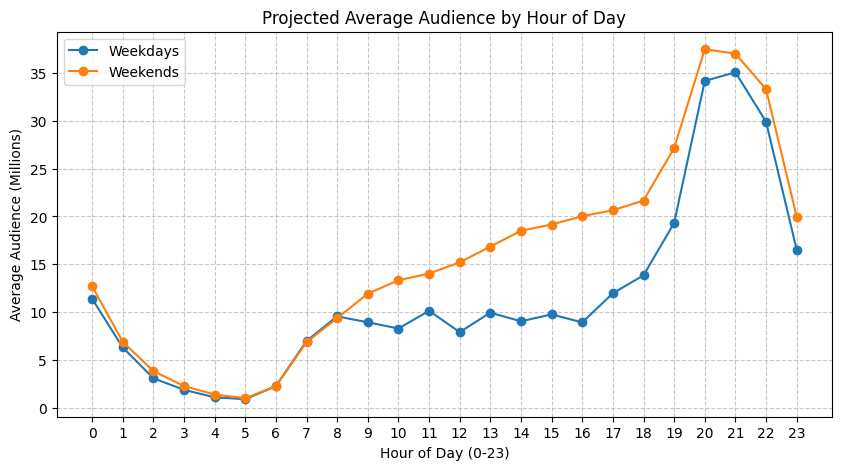

Peak hour, weekdays: 21
Peak hour, weekends: 20


In [27]:
tv_datetime = v_exploded['minute_list'] - pd.Timedelta(hours=6)
v_exploded['is_weekend'] = tv_datetime.dt.dayofweek >= 5

dates = pd.to_datetime(daily_weights['broadcast_date'].unique())
n_weekends = (dates.dayofweek >= 5).sum()
n_weekdays = len(dates) - n_weekends

hourly = v_exploded.groupby(['hour', 'is_weekend'])['weight'].sum().reset_index()

hourly['avg_aud_M'] = hourly.apply(
    lambda r: (r['weight'] / 60 / n_weekends / 1_000_000) if r['is_weekend'] else (r['weight'] / 60 / n_weekdays / 1_000_000),
    axis=1
)

wd_data = hourly[hourly['is_weekend'] == False].sort_values('hour')
we_data = hourly[hourly['is_weekend'] == True].sort_values('hour')

plt.figure(figsize=(10, 5))
plt.plot(wd_data['hour'], wd_data['avg_aud_M'], marker='o', label='Weekdays')
plt.plot(we_data['hour'], we_data['avg_aud_M'], marker='o', label='Weekends')
plt.title('Projected Average Audience by Hour of Day')
plt.xlabel('Hour of Day (0-23)')
plt.ylabel('Average Audience (Millions)')
plt.xticks(range(24))
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()

print("Peak hour, weekdays:", wd_data.loc[wd_data['avg_aud_M'].idxmax(), 'hour'])
print("Peak hour, weekends:", we_data.loc[we_data['avg_aud_M'].idxmax(), 'hour'])

**Answer:** how the weekend differs.

On weekends, TV viewership is notably higher during daytime hours, particularly from 08:00 to 19:00, as people are typically at home rather than at work or school. During the night and early morning (00:00 to 08:00), there is virtually no difference in audience size. Both weekdays and weekends share a prime-time peak at 20:00, after which the viewing steadily declines.

## Task 1.3 — Session length

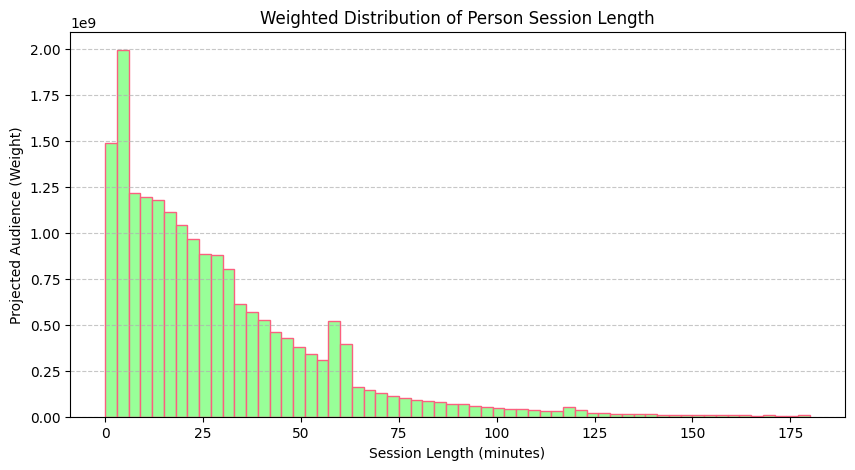

Session length, weighted mean (min): 29.4
Session length, weighted median (min): 21.0


In [28]:
v_sessions = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()

v_sessions['length_min'] = (v_sessions['end_ts'] - v_sessions['start_ts']).dt.total_seconds() / 60

weighted_mean = (v_sessions['length_min'] * v_sessions['weight']).sum() / v_sessions['weight'].sum()

v_sessions_sorted = v_sessions.sort_values('length_min')
cum_weights = v_sessions_sorted['weight'].cumsum()
cutoff = v_sessions_sorted['weight'].sum() / 2.0
weighted_median = v_sessions_sorted[cum_weights >= cutoff]['length_min'].iloc[0]

plt.figure(figsize=(10, 5))
plt.hist(v_sessions['length_min'], bins=60, weights=v_sessions['weight'], range=(0, 180), color='#98FF98', edgecolor='#FB607F')
plt.title('Weighted Distribution of Person Session Length')
plt.xlabel('Session Length (minutes)')
plt.ylabel('Projected Audience (Weight)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

print(f"Session length, weighted mean (min): {weighted_mean:.1f}")
print(f"Session length, weighted median (min): {weighted_median:.1f}")

**Answer:** why mean and median differ; which one you would show a client.

The mean is significantly higher than the median because the distribution of session lengths is heavily right-skewed. A small number of very long viewing sessions (the long right tail) pulls the mathematical average up. I would present the median to a client because it provides a much more honest and accurate representation of a "typical" viewer's engagement, without being artificially inflated by extreme outliers.

## Task 2 — Program reach curve

In [29]:
cbs_news = programs[(programs['program_name'] == 'CBS Evening News') &
                    (programs['network_code'] == 'CBS')].copy()
cbs_news = cbs_news.sort_values('start_ts')

cbs_viewings = viewings[viewings['network_code'] == 'CBS'].copy()

hh_ratings = []
p2_ratings = []
proj_audiences = []

for _, telecast in cbs_news.iterrows():
    b_date = telecast['broadcast_date']

    overlap = cbs_viewings[
        (cbs_viewings['start_ts'] < telecast['end_ts']) &
        (cbs_viewings['end_ts'] > telecast['start_ts'])
    ]

    hh_watched = overlap[overlap['resp_type'] == 'H']
    p2_watched = overlap[overlap['resp_type'].isin(['R', 'L'])]

    hh_watched_weight = hh_watched.drop_duplicates('respondent_id')['weight'].sum()
    p2_watched_weight = p2_watched.drop_duplicates('respondent_id')['weight'].sum()

    day_weights = daily_weights[daily_weights['broadcast_date'] == b_date]

    hh_universe = day_weights[day_weights['resp_type'] == 'H']['weight'].sum()
    p2_universe = day_weights[day_weights['resp_type'].isin(['R', 'L'])]['weight'].sum()

    hh_rating_val = (hh_watched_weight / hh_universe) * 100
    p2_rating_val = (p2_watched_weight / p2_universe) * 100
    proj_aud_val = p2_watched_weight / 1_000_000

    hh_ratings.append(hh_rating_val)
    p2_ratings.append(p2_rating_val)
    proj_audiences.append(proj_aud_val)

cbs_news['hh_rating'] = hh_ratings
cbs_news['p2_rating'] = p2_ratings
cbs_news['proj_aud_M'] = proj_audiences

print("Telecasts of the program:", len(cbs_news))
print("Average household rating (%):", round(cbs_news['hh_rating'].mean(), 1))
print("Average P2+ rating (%):", round(cbs_news['p2_rating'].mean(), 1))
print("Average projected audience (M):", round(cbs_news['proj_aud_M'].mean(), 2))

Telecasts of the program: 23
Average household rating (%): 3.2
Average P2+ rating (%): 1.6
Average projected audience (M): 4.93


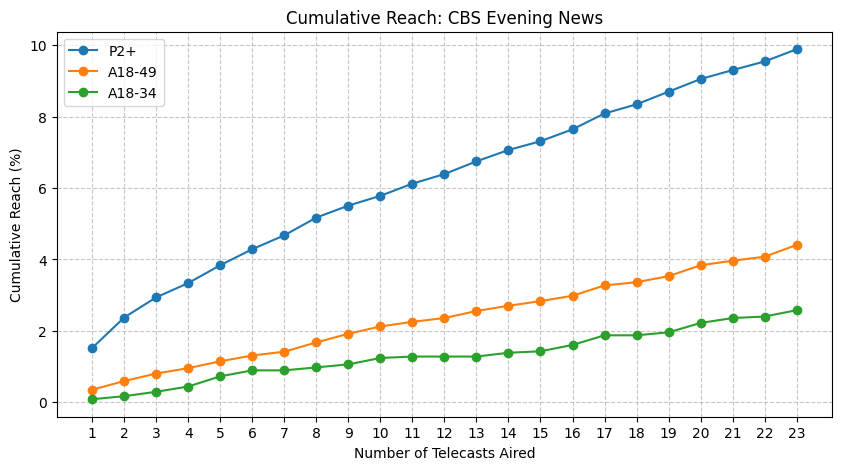

Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4


In [30]:
monthly_weights = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])].groupby('respondent_id')['weight'].mean().reset_index()
monthly_weights = monthly_weights.rename(columns={'weight': 'avg_weight'})

attrs_merged = pd.merge(viewer_attributes, attributes, on='attr_id')

exact_ages = attrs_merged[attrs_merged['attr_id'] == 300][['respondent_id', 'value']].rename(columns={'value': 'exact_age'})
band_ages = attrs_merged[attrs_merged['attr_group'] == 'Age band'][['respondent_id', 'attr_name']].rename(columns={'attr_name': 'age_band'})

persons_info = pd.merge(monthly_weights, exact_ages, on='respondent_id', how='left')
persons_info = pd.merge(persons_info, band_ages, on='respondent_id', how='left')

def is_18_34(row):
    if pd.notnull(row['exact_age']):
        return 18 <= row['exact_age'] <= 34
    if pd.notnull(row['age_band']):
        return row['age_band'] in ['18-20', '21-24', '25-34']
    return False

def is_18_49(row):
    if pd.notnull(row['exact_age']):
        return 18 <= row['exact_age'] <= 49
    if pd.notnull(row['age_band']):
        return row['age_band'] in ['18-20', '21-24', '25-34', '35-49']
    return False

persons_info['is_18_34'] = persons_info.apply(is_18_34, axis=1)
persons_info['is_18_49'] = persons_info.apply(is_18_49, axis=1)

p2_universe = persons_info['avg_weight'].sum()
a18_34_universe = persons_info[persons_info['is_18_34']]['avg_weight'].sum()
a18_49_universe = persons_info[persons_info['is_18_49']]['avg_weight'].sum()

seen_p2 = set()
reach_p2, reach_a18_34, reach_a18_49 = [], [], []

for _, telecast in cbs_news.iterrows():
    overlap = cbs_viewings[(cbs_viewings['start_ts'] < telecast['end_ts']) & (cbs_viewings['end_ts'] > telecast['start_ts'])]
    viewers_this_episode = overlap[overlap['resp_type'].isin(['R', 'L'])]['respondent_id'].unique()

    seen_p2.update(viewers_this_episode)
    reached = persons_info[persons_info['respondent_id'].isin(seen_p2)]

    r_p2 = reached['avg_weight'].sum() / p2_universe * 100
    r_18_34 = reached[reached['is_18_34']]['avg_weight'].sum() / a18_34_universe * 100
    r_18_49 = reached[reached['is_18_49']]['avg_weight'].sum() / a18_49_universe * 100

    reach_p2.append(r_p2)
    reach_a18_34.append(r_18_34)
    reach_a18_49.append(r_18_49)

plt.figure(figsize=(10, 5))
plt.plot(range(1, 24), reach_p2, marker='o', label='P2+')
plt.plot(range(1, 24), reach_a18_49, marker='o', label='A18-49')
plt.plot(range(1, 24), reach_a18_34, marker='o', label='A18-34')
plt.title('Cumulative Reach: CBS Evening News')
plt.xlabel('Number of Telecasts Aired')
plt.ylabel('Cumulative Reach (%)')
plt.xticks(range(1, 24))
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()

print("Final reach P2+ (%):", round(reach_p2[-1], 1))
print("Final reach A18-34 (%):", round(reach_a18_34[-1], 1))
print("Final reach A18-49 (%):", round(reach_a18_49[-1], 1))

**Answer:** reach vs rating; which audience is reached best, and why.

Cumulative reach keeps growing because even though the daily rating remains relatively flat, different people tune in on different days, constantly adding new unique viewers to the total count. The program reaches the general audience (P2+) much better than the younger demographics (A18-34 and A18-49), which have the lowest reach. This aligns perfectly with the known behavior of traditional network evening news audiences, which heavily skew toward older generations, while younger viewers typically consume news via digital platforms.


## Task 3 — Program frequency

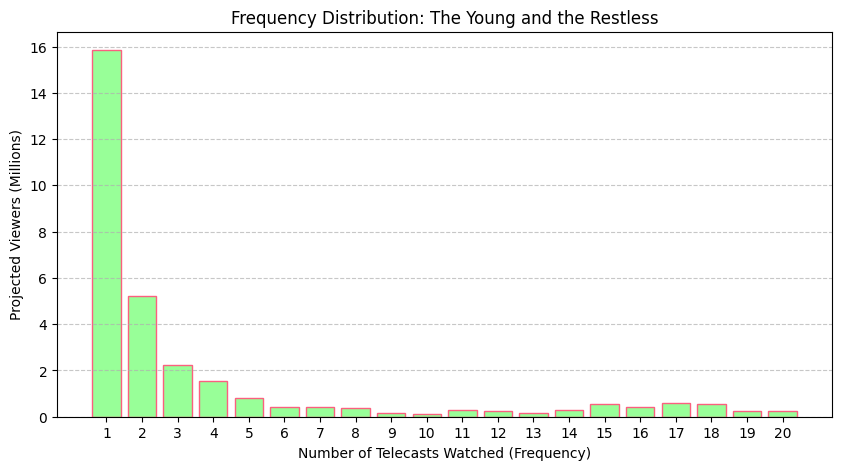

Projected viewers (M): 30.8
Average frequency (weighted): 3.63
Median frequency (weighted): 1
Share of views from the most loyal viewers: 0.704


In [31]:
soap_telecasts = programs[(programs['program_name'] == 'The Young and the Restless') &
                          (programs['network_code'] == 'CBS')]

watched_records = []
for idx, telecast in soap_telecasts.iterrows():
    overlap = cbs_viewings[
        (cbs_viewings['start_ts'] < telecast['end_ts']) &
        (cbs_viewings['end_ts'] > telecast['start_ts']) &
        (cbs_viewings['resp_type'].isin(['R', 'L']))
    ]
    unique_viewers = overlap['respondent_id'].unique()
    for uid in unique_viewers:
        watched_records.append({'respondent_id': uid, 'telecast_id': telecast['telecast_id']})

watched_df = pd.DataFrame(watched_records)
freq_df = watched_df.groupby('respondent_id').size().reset_index(name='frequency')

freq_df = pd.merge(freq_df, monthly_weights, on='respondent_id', how='inner')

proj_viewers_m = freq_df['avg_weight'].sum() / 1_000_000
weighted_avg_freq = (freq_df['frequency'] * freq_df['avg_weight']).sum() / freq_df['avg_weight'].sum()

freq_sorted = freq_df.sort_values('frequency')
cum_weights = freq_sorted['avg_weight'].cumsum()
cutoff_50 = freq_sorted['avg_weight'].sum() / 2.0
weighted_median_freq = freq_sorted[cum_weights >= cutoff_50]['frequency'].iloc[0]

cutoff_80 = freq_sorted['avg_weight'].sum() * 0.80
percentile_80_freq = freq_sorted[cum_weights >= cutoff_80]['frequency'].iloc[0]

total_views = (freq_df['frequency'] * freq_df['avg_weight']).sum()
loyal_views = (freq_df[freq_df['frequency'] >= percentile_80_freq]['frequency'] *
               freq_df[freq_df['frequency'] >= percentile_80_freq]['avg_weight']).sum()
loyal_share = loyal_views / total_views

dist_df = freq_df.groupby('frequency')['avg_weight'].sum().reset_index()
dist_df['aud_M'] = dist_df['avg_weight'] / 1_000_000

plt.figure(figsize=(10, 5))
plt.bar(dist_df['frequency'], dist_df['aud_M'], color='#98FF98', edgecolor='#FB607F')
plt.title('Frequency Distribution: The Young and the Restless')
plt.xlabel('Number of Telecasts Watched (Frequency)')
plt.ylabel('Projected Viewers (Millions)')
plt.xticks(range(1, int(dist_df['frequency'].max()) + 1))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

print("Projected viewers (M):", round(proj_viewers_m, 2))
print("Average frequency (weighted):", round(weighted_avg_freq, 2))
print("Median frequency (weighted):", int(weighted_median_freq))
print("Share of views from the most loyal viewers:", round(loyal_share, 3))

**Answer:** is the average frequency a fair summary?

No, the average frequency is not a fair summary because the distribution is highly polarized (a U-shape or heavy skew). The vast majority of people watched only 1 or 2 episodes, while a small but highly dedicated group of "super fans" watched almost all of them (20+ episodes). These loyal viewers pull the mathematical average up, making it seem like the "typical" viewer watches several episodes. In reality, almost nobody watches exactly the average amount; viewers are either casual drop-ins or everyday watchers. The median is a much more honest representation of the typical viewer's behavior.

##Task 4 — Networks by age and gender

In [32]:
v_adults = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()
v_adults['minutes'] = (v_adults['end_ts'] - v_adults['start_ts']).dt.total_seconds() / 60
v_adults['proj_minutes'] = v_adults['minutes'] * v_adults['weight']
sex_data = attrs_merged[attrs_merged['attr_group'] == 'Sex'][['respondent_id', 'attr_name']].rename(columns={'attr_name': 'sex'})

v_adults = pd.merge(v_adults, persons_info[['respondent_id', 'exact_age', 'age_band']], on='respondent_id', how='left')
v_adults = pd.merge(v_adults, sex_data, on='respondent_id', how='left')

def get_audience(row):
    prefix = 'M' if row['sex'] == 'Male' else 'W' if row['sex'] == 'Female' else None
    if not prefix: return None

    age = row['exact_age']
    age_b = str(row['age_band']) if pd.notnull(row['age_band']) else ""

    if pd.notnull(age):
        if 18 <= age <= 34: return f"{prefix}18-34"
        elif 35 <= age <= 54: return f"{prefix}35-54"
        elif age >= 55: return f"{prefix}55+"
    else:
        if age_b in ['18-20', '21-24', '25-34']: return f"{prefix}18-34"
        elif age_b in ['35-49', '50-54']: return f"{prefix}35-54"
        elif age_b in ['55-64', '65+']: return f"{prefix}55+"

    return None

v_adults['audience'] = v_adults.apply(get_audience, axis=1)
v_adults = v_adults[v_adults['audience'].notnull()]

audiences = ['M18-34', 'W18-34', 'M35-54', 'W35-54', 'M55+', 'W55+']
print("--- TOP 5 NETWORKS BY AUDIENCE ---")
for aud in audiences:
    top_5 = v_adults[v_adults['audience'] == aud].groupby('network_code')['proj_minutes'].sum().nlargest(5)
    print(f"\n{aud}:")
    for net, mins in top_5.items():
        print(f"  {net}: {mins / 1_000_000_000:.2f}B mins")

v_adults['is_18_34'] = v_adults['audience'].isin(['M18-34', 'W18-34'])

weighted_share = v_adults.groupby('network_code').apply(
    lambda x: x[x['is_18_34']]['proj_minutes'].sum() / x['proj_minutes'].sum()
)

raw_share = v_adults.groupby('network_code').apply(
    lambda x: x[x['is_18_34']]['minutes'].sum() / x['minutes'].sum()
)

youngest = weighted_share.idxmax()
oldest = weighted_share.idxmin()

print("\nAGE DEMOGRAPHICS")
print(f"Youngest network: {youngest} ({weighted_share[youngest]:.3f})")
print(f"Oldest network: {oldest} ({weighted_share[oldest]:.3f})")

print("\n18-34 SHARE COMPARISON (Weighted vs Raw)")
comparison_df = pd.DataFrame({'Weighted': weighted_share, 'Raw': raw_share}).round(3)
print(comparison_df)

--- TOP 5 NETWORKS BY AUDIENCE ---

M18-34:
  FOX: 4.39B mins
  NBC: 3.91B mins
  CBS: 3.04B mins
  ABC: 3.01B mins
  FX: 1.47B mins

W18-34:
  FOX: 4.57B mins
  NBC: 4.53B mins
  ABC: 3.50B mins
  CBS: 2.81B mins
  FX: 1.38B mins

M35-54:
  FOX: 12.80B mins
  NBC: 10.99B mins
  ABC: 9.04B mins
  CBS: 8.13B mins
  FX: 2.37B mins

W35-54:
  NBC: 11.64B mins
  FOX: 11.16B mins
  ABC: 9.44B mins
  CBS: 8.16B mins
  HGTV: 3.05B mins

M55+:
  CBS: 38.27B mins
  NBC: 34.27B mins
  FOX: 30.88B mins
  ABC: 30.79B mins
  FNC: 27.90B mins

W55+:
  CBS: 47.12B mins
  NBC: 41.39B mins
  ABC: 38.84B mins
  FOX: 36.91B mins
  FNC: 31.45B mins

AGE DEMOGRAPHICS
Youngest network: FX (0.294)
Oldest network: FNC (0.018)

18-34 SHARE COMPARISON (Weighted vs Raw)
              Weighted    Raw
network_code                 
ABC              0.069  0.065
BRAVO            0.158  0.135
CBS              0.054  0.053
FNC              0.018  0.017
FOOD             0.086  0.079
FOX              0.089  0.083
FX    

/tmp/ipykernel_802/2614172408.py:40: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  weighted_share = v_adults.groupby('network_code').apply(
/tmp/ipykernel_802/2614172408.py:44: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  raw_share = v_adults.groupby('network_code').apply(


**Answer:** weighted vs raw.

The 18-34 audience share is consistently lower in the raw data than in the weighted data across all networks (e.g., FX is 25.3% raw vs. 29.4% weighted). This indicates that young adults are underrepresented in the physical panel, likely because they are harder to recruit or less compliant with using the people meters. The weights correct this imbalance to match the actual US population. If you reported raw numbers to a client, you would severely underestimate the young audience, causing advertisers to undervalue the network.

**Bonus answer:** the sales pitch.

Although FNC has the oldest demographic and the lowest percentage of 18-34 viewers (1.8%), its total overall audience is massive. I would pitch that the young adults tuning into FNC represent an exclusive, serious-minded, and highly engaged niche (such as young professionals or affluent voters) that advertisers simply cannot reach on typical entertainment networks. Furthermore, many of them might be co-viewing with older, high-income family members.